Conductor types:
  1 - Solid round
  2 - Stranded, 7 strands
  3 - Stranded, 19 strands
  4 - Stranded, 37 strands
  5 - ACSR 26/7


Select conductor type (1-5):  3
Enter physical radius of each subconductor (m):  0.04



Subconductors per bundle:
  2 - Two subconductors
  3 - Three subconductors
  4 - Four subconductors


Select number of subconductors per bundle (2-4):  3
Enter adjacent subconductor spacing within each bundle (m):  0.09
Enter vertical spacing between phases A and B (m):  1.5
Enter vertical spacing between phases B and C (m):  1.5
Enter horizontal spacing between corresponding circuits (m):  1.2


,Parameter,Value
0,Conductor type,"Stranded, 19 strands"
1,Subconductors per bundle,3
2,Subconductor radius (m),0.04
3,Single-subconductor GMR (m),0.03032
4,Bundle spacing (m),0.09
5,Bundle GMR (m),0.062624
6,Bundle capacitance radius (m),0.068683
7,Phase spacing D_AB (m),1.5
8,Phase spacing D_BC (m),1.5
9,Circuit spacing D_CC (m),1.2


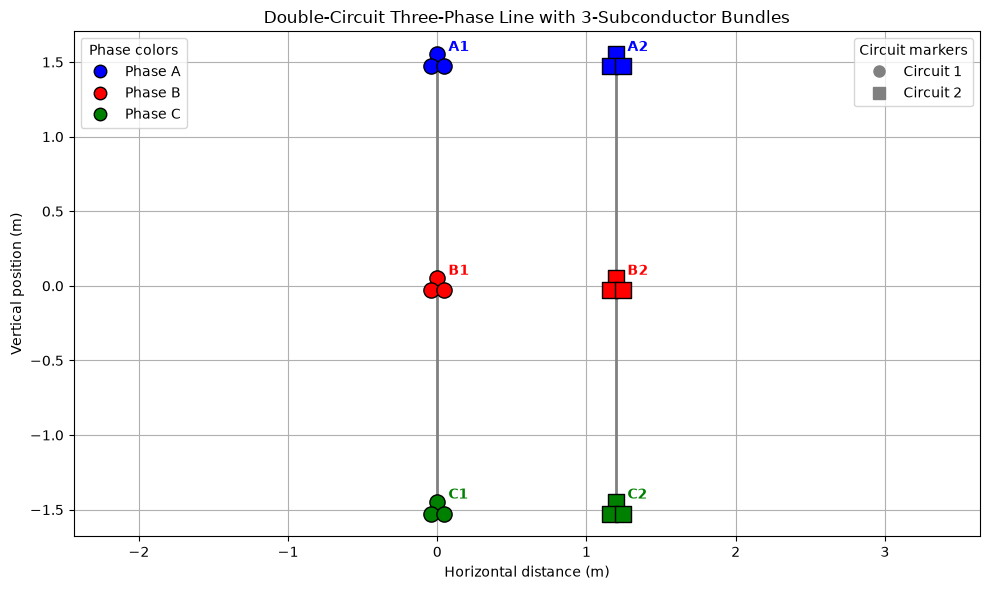

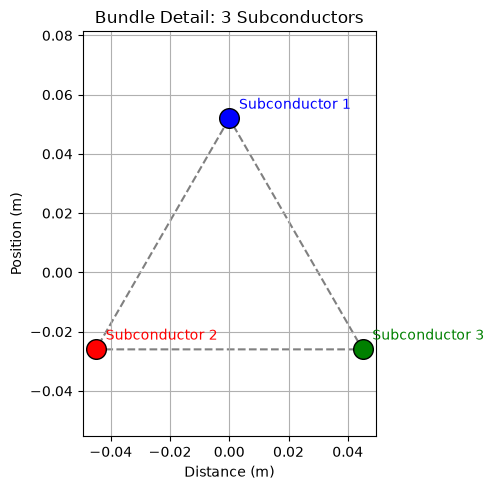

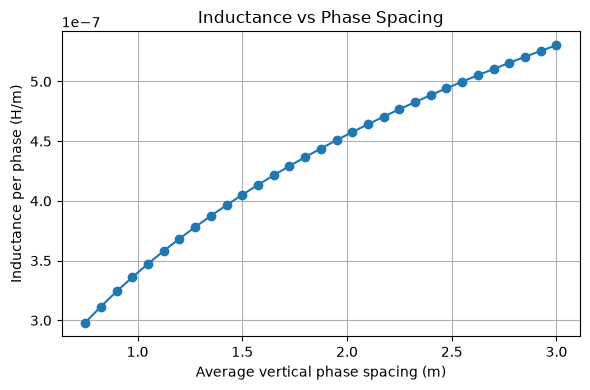

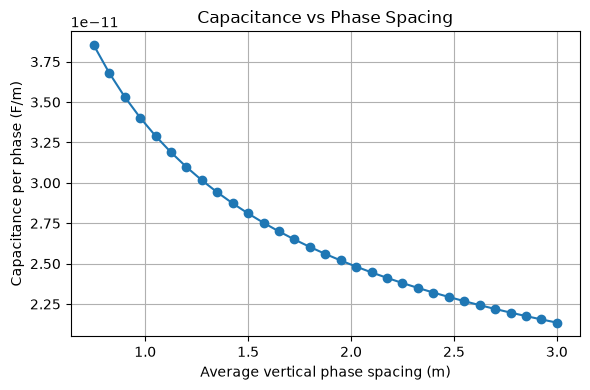

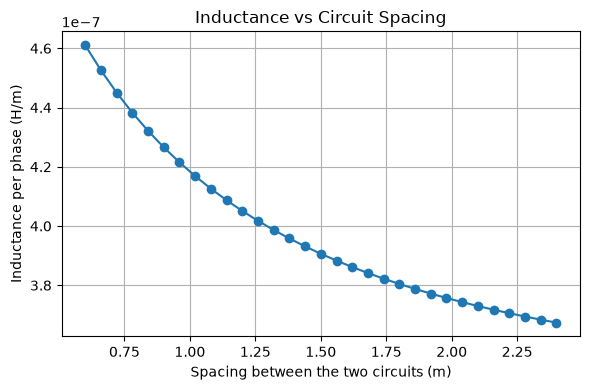

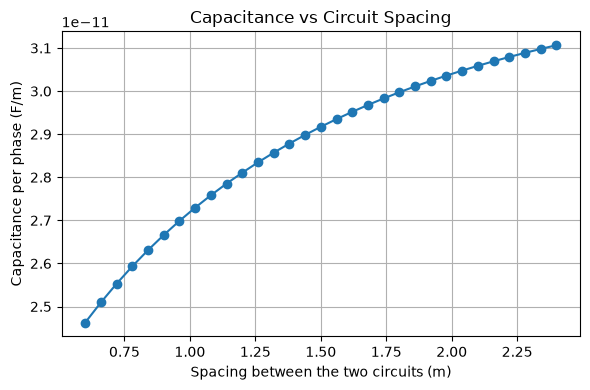

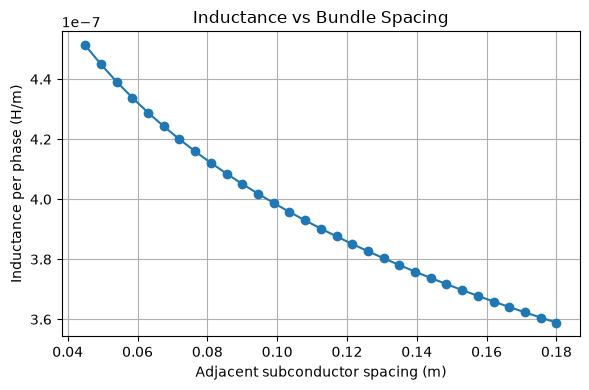

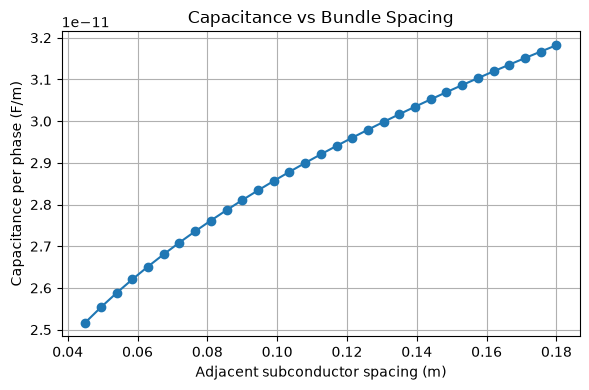

,Subconductors per bundle,Bundle GMR (m),Bundle radius (m),Equivalent phase GMR (m),Inductance per phase (H/m),Capacitance per phase (F/m)
0,2,0.052238,0.060000,0.250371,4.232289e-07,2.717864e-11
1,3,0.062624,0.068683,0.274132,4.050955e-07,2.810658e-11
2,4,0.074773,0.080136,0.299545,3.873645e-07,2.924596e-11


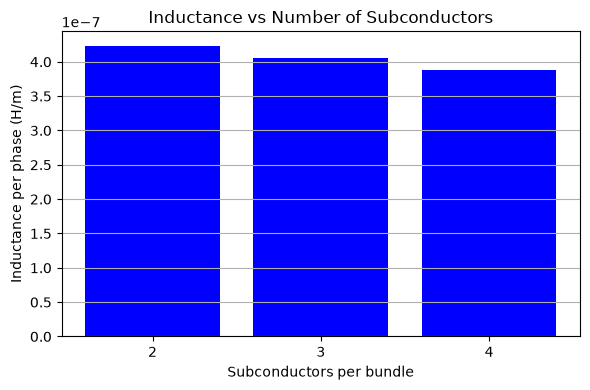

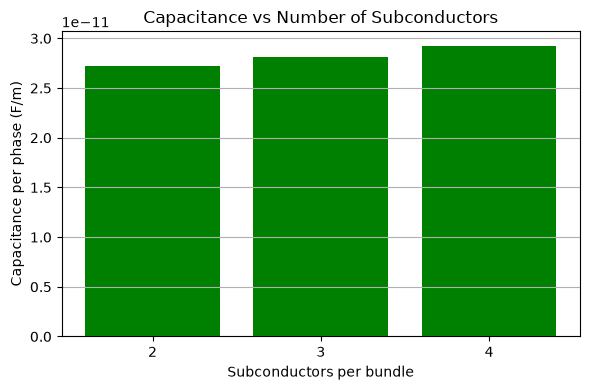


--- Conclusions ---
Each phase has a bundle in both circuits. Corresponding bundles are combined using the composite-conductor approximation.
Changing phase spacing changes the mutual GMD between phase groups.
Changing circuit spacing changes the equivalent phase self value and the mutual GMDs.
Changing bundle spacing or subconductor count changes the bundle GMR and capacitance radius.
Inductance and capacitance are calculated per phase per metre.


In [3]:
# ============================================================
# DOUBLE-CIRCUIT THREE-PHASE LINE WITH BUNDLED CONDUCTORS
# GMR, GMD, INDUCTANCE, CAPACITANCE AND GRAPHS
# ============================================================

import math
import matplotlib.pyplot as plt
import pandas as pd


# -------------------------
# 1. Input helper functions
# -------------------------

def read_positive_float(prompt):
    """Ask until the user enters a positive numeric value."""
    while True:
        try:
            value = float(input(prompt))
            if math.isfinite(value) and value > 0:
                return value
            print("Enter a finite number greater than zero.")
        except ValueError:
            print("Invalid input. Enter a numeric value.")


def read_menu_choice(prompt, choices):
    """Ask until the user selects a valid menu option."""
    while True:
        choice = input(prompt).strip()
        if choice in choices:
            return choice
        print(f"Invalid choice. Select one of: {', '.join(choices)}")


# -------------------------
# 2. Conductor inputs
# -------------------------

conductor_types = {
    "1": ("Solid round", 0.7788),
    "2": ("Stranded, 7 strands", 0.726),
    "3": ("Stranded, 19 strands", 0.758),
    "4": ("Stranded, 37 strands", 0.768),
    "5": ("ACSR 26/7", 0.81),
}

print("Conductor types:")
for key, (name, _) in conductor_types.items():
    print(f"  {key} - {name}")

choice = read_menu_choice(
    "Select conductor type (1-5): ",
    list(conductor_types.keys())
)

conductor_name, gmr_factor = conductor_types[choice]

r = read_positive_float(
    "Enter physical radius of each subconductor (m): "
)

# Approximate GMR of one subconductor
GMR_single = gmr_factor * r
epsilon_0 = 8.854e-12


# -------------------------
# 3. Bundle inputs
# -------------------------

print("\nSubconductors per bundle:")
print("  2 - Two subconductors")
print("  3 - Three subconductors")
print("  4 - Four subconductors")

N = int(read_menu_choice(
    "Select number of subconductors per bundle (2-4): ",
    ["2", "3", "4"]
))

bundle_spacing = read_positive_float(
    "Enter adjacent subconductor spacing within each bundle (m): "
)


# -------------------------
# 4. Double-circuit geometry inputs
# -------------------------

D_AB = read_positive_float(
    "Enter vertical spacing between phases A and B (m): "
)

D_BC = read_positive_float(
    "Enter vertical spacing between phases B and C (m): "
)

D_CC = read_positive_float(
    "Enter horizontal spacing between corresponding circuits (m): "
)


# -------------------------
# 5. Bundle and line calculation functions
# -------------------------

def bundle_positions(number, spacing):
    """Return subconductor coordinates relative to the bundle center."""

    radius_from_center = spacing / (2 * math.sin(math.pi / number))
    starting_angles = {2: 0, 3: 90, 4: 45}
    starting_angle = math.radians(starting_angles[number])

    angles = [
        starting_angle + 2 * math.pi * k / number
        for k in range(number)
    ]

    return [
        (
            radius_from_center * math.cos(angle),
            radius_from_center * math.sin(angle)
        )
        for angle in angles
    ]


def bundle_values(number, spacing):
    """
    Calculate bundle GMR for inductance and equivalent bundle
    radius for capacitance.
    """

    offsets = bundle_positions(number, spacing)

    product_gmr = GMR_single
    product_radius = r

    # Distances from the first subconductor to the others
    for j in range(1, number):
        distance = math.hypot(
            offsets[0][0] - offsets[j][0],
            offsets[0][1] - offsets[j][1]
        )

        if distance <= 0:
            raise ValueError("Subconductors overlap within the bundle.")

        product_gmr *= distance
        product_radius *= distance

    bundle_gmr = product_gmr ** (1 / number)
    bundle_radius = product_radius ** (1 / number)

    return bundle_gmr, bundle_radius


def phase_centers(D_AB, D_BC, D_CC):
    """Return phase-center coordinates for both circuits."""

    heights = {
        "A": D_BC,
        "B": 0.0,
        "C": -D_AB,
    }

    return {
        phase: [
            (0.0, height),
            (D_CC, height)
        ]
        for phase, height in heights.items()
    }


def point_distance(point_1, point_2):
    return math.hypot(
        point_1[0] - point_2[0],
        point_1[1] - point_2[1]
    )


def two_circuit_gmd(phase_1_centers, phase_2_centers):
    """Calculate GMD between two phase groups in the two circuits."""

    distances = [
        point_distance(point_1, point_2)
        for point_1 in phase_1_centers
        for point_2 in phase_2_centers
    ]

    if any(distance <= 0 for distance in distances):
        raise ValueError("Phase conductors overlap.")

    return math.prod(distances) ** (1 / len(distances))


def calculate_line_parameters(
    D_AB,
    D_BC,
    D_CC,
    number,
    spacing
):
    """
    Calculate double-circuit equivalent GMR, GMD, inductance
    and capacitance.

    The two identical phase bundles, one in each circuit, are
    combined using the composite-conductor approximation:
        equivalent self value = sqrt(bundle value * circuit spacing)
    """

    if min(D_AB, D_BC, D_CC, spacing) <= 0:
        raise ValueError("All spacings must be greater than zero.")

    bundle_gmr, bundle_radius = bundle_values(number, spacing)

    # Equivalent self GMR and capacitance radius for both circuits
    GMR_phase = math.sqrt(bundle_gmr * D_CC)
    radius_phase = math.sqrt(bundle_radius * D_CC)

    centers = phase_centers(D_AB, D_BC, D_CC)

    GMD_AB = two_circuit_gmd(centers["A"], centers["B"])
    GMD_BC = two_circuit_gmd(centers["B"], centers["C"])
    GMD_CA = two_circuit_gmd(centers["C"], centers["A"])

    # Overall GMD for the transposed three-phase line
    GMD_overall = (GMD_AB * GMD_BC * GMD_CA) ** (1 / 3)

    if GMD_overall <= GMR_phase:
        raise ValueError(
            "Overall GMD must be greater than the equivalent phase GMR. "
            "Check the entered spacings."
        )

    if GMD_overall <= radius_phase:
        raise ValueError(
            "Overall GMD must be greater than the equivalent phase radius. "
            "Check the entered spacings."
        )

    # Inductance per phase per metre (H/m)
    inductance = 2e-7 * math.log(GMD_overall / GMR_phase)

    # Capacitance per phase per metre (F/m)
    capacitance = (
        2 * math.pi * epsilon_0
        / math.log(GMD_overall / radius_phase)
    )

    return {
        "bundle_gmr": bundle_gmr,
        "bundle_radius": bundle_radius,
        "GMR_phase": GMR_phase,
        "radius_phase": radius_phase,
        "GMD_AB": GMD_AB,
        "GMD_BC": GMD_BC,
        "GMD_CA": GMD_CA,
        "GMD_overall": GMD_overall,
        "inductance": inductance,
        "capacitance": capacitance,
    }


# Calculate line parameters using the entered geometry
result = calculate_line_parameters(
    D_AB,
    D_BC,
    D_CC,
    N,
    bundle_spacing
)


# -------------------------
# 6. Display calculated results
# -------------------------

summary = pd.DataFrame({
    "Parameter": [
        "Conductor type",
        "Subconductors per bundle",
        "Subconductor radius (m)",
        "Single-subconductor GMR (m)",
        "Bundle spacing (m)",
        "Bundle GMR (m)",
        "Bundle capacitance radius (m)",
        "Phase spacing D_AB (m)",
        "Phase spacing D_BC (m)",
        "Circuit spacing D_CC (m)",
        "Equivalent double-circuit phase GMR (m)",
        "Equivalent double-circuit phase radius (m)",
        "GMD_AB (m)",
        "GMD_BC (m)",
        "GMD_CA (m)",
        "Overall GMD (m)",
        "Inductance per phase (H/m)",
        "Capacitance per phase (F/m)",
    ],
    "Value": [
        conductor_name,
        N,
        r,
        GMR_single,
        bundle_spacing,
        result["bundle_gmr"],
        result["bundle_radius"],
        D_AB,
        D_BC,
        D_CC,
        result["GMR_phase"],
        result["radius_phase"],
        result["GMD_AB"],
        result["GMD_BC"],
        result["GMD_CA"],
        result["GMD_overall"],
        result["inductance"],
        result["capacitance"],
    ],
})

display(summary)


# -------------------------
# 7. Plot the double-circuit layout
# -------------------------

offsets = bundle_positions(N, bundle_spacing)

phase_colors = {"A": "blue","B": "red","C": "green",}
phase_heights = {"A": D_BC,"B": 0.0,"C": -D_AB,}
plt.figure(figsize=(10, 6))
for phase in ["A", "B", "C"]:
color = phase_colors[phase] y_center = phase_heights[phase]
for circuit_number, x_center in enumerate([0.0, D_CC], start=1):marker = "o"
if circuit_number == 1 else "s"xs = [x_center + dx for dx, dy in offsets]ys = [y_center + dy for dx, dy in offsets]
plt.scatter(xs,ys,
color=color,marker=marker,s=120,edgecolors="black",zorder=3)
plt.annotate(f"{phase}{circuit_number}",(x_center, y_center),xytext=(8, 8),textcoords="offset points",color=color,fontweight="bold")
# Draw the two support columns
plt.plot([0, 0], [-D_AB, D_BC], color="gray", linewidth=2)
plt.plot([D_CC, D_CC], [-D_AB, D_BC], color="gray", linewidth=2)
phase_legend = [
plt.Line2D([0], [0],marker="o",color="w",
markerfacecolor=phase_colors[phase],markeredgecolor="black",label=f"Phase {phase}",markersize=9)
for phase in ["A", "B", "C"]]
circuit_legend = [plt.Line2D([0], [0],marker="o",color="gray",linestyle="None",
label="Circuit 1",markersize=8),
plt.Line2D([0], [0],marker="s",color="gray",linestyle="None",label="Circuit 2",markersize=8),]
plt.title(f"Double-Circuit Three-Phase Line with "f"{N}-Subconductor Bundles")
plt.xlabel("Horizontal distance (m)")
plt.ylabel("Vertical position (m)")
plt.axis("equal")
plt.grid(True)
phase_legend_artist = plt.legend(handles=phase_legend,title="Phase colors",loc="upper left")
plt.gca().add_artist(phase_legend_artist)
plt.legend(handles=circuit_legend,title="Circuit markers",loc="upper right")
plt.tight_layout()
plt.show()
# Step:8. Show one bundle in detail
bundle_colors = ["blue", "red", "green"]
bx = [point[0] for point in offsets]
by = [point[1] for point in offsets]
plt.figure(figsize=(5, 5))
plt.plot(bx + [bx[0]],by + [by[0]],linestyle="--",color="gray",zorder=1)
for i, (x, y) in enumerate(zip(bx, by)):
color = bundle_colors[i % len(bundle_colors)]
plt.scatter(x,y,s=200,color=color,edgecolors="black",zorder=3)
plt.annotate(f"Subconductor {i + 1}",(x, y),xytext=(7, 7),textcoords="offset points",color=color)
plt.title(f"Bundle Detail: {N} Subconductors")
plt.xlabel("Distance (m)")
plt.ylabel("Position (m)")
plt.axis("equal")
plt.grid(True)
plt.tight_layout()
plt.show()
#Step: 9. Inductance and capacitance
#    versus phase spacing
# Scale both phase spacings together, preserving their ratio.
phase_factors = [0.5 + 0.05 * i for i in range(31)]
phase_spacing_values = []
phase_inductances = []
phase_capacitances = []
for factor in phase_factors:
try:
values = calculate_line_parameters(D_AB * factor,D_BC * factor,D_CC,N,bundle_spacing)
phase_spacing_values.append((D_AB * factor + D_BC * factor) / 2)
phase_inductances.append(values["inductance"])
phase_capacitances.append(values["capacitance"])
except ValueError:
continue
plt.figure(figsize=(6, 4))
plt.plot(phase_spacing_values, phase_inductances, marker="o")
plt.title("Inductance vs Phase Spacing")
plt.xlabel("Average vertical phase spacing (m)")
plt.ylabel("Inductance per phase (H/m)")
plt.grid(True)
plt.tight_layout()
plt.show()
plt.figure(figsize=(6, 4))
plt.plot(phase_spacing_values, phase_capacitances, marker="o")
plt.title("Capacitance vs Phase Spacing")
plt.xlabel("Average vertical phase spacing (m)")
plt.ylabel("Capacitance per phase (F/m)")
plt.grid(True)
plt.tight_layout()
plt.show()
# Step:10. Inductance and capacitance
# versus circuit spacing
circuit_factors = [0.5 + 0.05 * i for i in range(31)]
circuit_spacing_values = []
circuit_inductances = []
circuit_capacitances = []
for factor in circuit_factors:
spacing = D_CC * factor
try:
values = calculate_line_parameters(D_AB,D_BC,spacing,N,bundle_spacing)
circuit_spacing_values.append(spacing)
circuit_inductances.append(values["inductance"])
circuit_capacitances.append(values["capacitance"])
except ValueError:
continue
plt.figure(figsize=(6, 4))
plt.plot(circuit_spacing_values, circuit_inductances, marker="o")
plt.title("Inductance vs Circuit Spacing")
plt.xlabel("Spacing between the two circuits (m)")
plt.ylabel("Inductance per phase (H/m)")
plt.grid(True)
plt.tight_layout()
plt.show()
plt.figure(figsize=(6, 4))
plt.plot(circuit_spacing_values, circuit_capacitances, marker="o")
plt.title("Capacitance vs Circuit Spacing")
plt.xlabel("Spacing between the two circuits (m)")
plt.ylabel("Capacitance per phase (F/m)")
plt.grid(True)
plt.tight_layout()
plt.show()
# Step:11. Inductance and capacitance
#versus bundle spacing
bundle_factors = [0.5 + 0.05 * i for i in range(31)]
bundle_spacing_values = []
bundle_inductances = []
bundle_capacitances = []
for factor in bundle_factors:
spacing = bundle_spacing * factor
try:
values = calculate_line_parameters(D_AB,D_BC,D_CC,N,spacing)
bundle_spacing_values.append(spacing)
bundle_inductances.append(values["inductance"])
bundle_capacitances.append(values["capacitance"])
except ValueError:
continue
plt.figure(figsize=(6, 4))
plt.plot(bundle_spacing_values, bundle_inductances, marker="o")
plt.title("Inductance vs Bundle Spacing")
plt.xlabel("Adjacent subconductor spacing (m)")
plt.ylabel("Inductance per phase (H/m)")
plt.grid(True)
plt.tight_layout()
plt.show()
plt.figure(figsize=(6, 4))
plt.plot(bundle_spacing_values, bundle_capacitances, marker="o")
plt.title("Capacitance vs Bundle Spacing")
plt.xlabel("Adjacent subconductor spacing (m)")
plt.ylabel("Capacitance per phase (F/m)")
plt.grid(True)
plt.tight_layout()
plt.show()
# Step: 12. Compare 2-, 3-, and 4-subconductor bundles
bundle_counts = [2, 3, 4]
count_results = []
for number in bundle_counts:
try:
values = calculate_line_parameters(D_AB,D_BC,D_CC,number,bundle_spacing)
count_results.append({
"Subconductors per bundle": number,
"Bundle GMR (m)": values["bundle_gmr"],
"Bundle radius (m)": values["bundle_radius"],
"Equivalent phase GMR (m)": values["GMR_phase"],
"Inductance per phase (H/m)": values["inductance"],
"Capacitance per phase (F/m)": values["capacitance"],})
except ValueError as error:
print(f"Skipping {number} subconductors per bundle: {error}")
count_table = pd.DataFrame(count_results)
if count_table.empty:
print("No valid results for the subconductor-count graphs.")
else:
display(count_table)
    # Bar chart: inductance versus subconductors per bundle
    plt.figure(figsize=(6, 4))
    plt.bar(count_table["Subconductors per bundle"].astype(str),count_table["Inductance per phase (H/m)"],color="blue")
    plt.title("Inductance vs Number of Subconductors")
    plt.xlabel("Subconductors per bundle")
    plt.ylabel("Inductance per phase (H/m)")
    plt.grid(True, axis="y")
    plt.tight_layout()
    plt.show()
    # Bar chart: capacitance versus subconductors per bundle
    plt.figure(figsize=(6, 4))
    plt.bar(count_table["Subconductors per bundle"].astype(str),count_table["Capacitance per phase (F/m)"],color="green")
    plt.title("Capacitance vs Number of Subconductors")
    plt.xlabel("Subconductors per bundle")
    plt.ylabel("Capacitance per phase (F/m)")
    plt.grid(True, axis="y")
    plt.tight_layout()
    plt.show()
# 13. Conclusions
print("\n--- Conclusions ---")
print(
    "Each phase has a bundle in both circuits. Corresponding bundles "
    "are combined using the composite-conductor approximation.")
print("Changing phase spacing changes the mutual GMD between phase groups.")
print(
    "Changing circuit spacing changes the equivalent phase self value "
    "and the mutual GMDs.")
print("Changing bundle spacing or subconductor count changes the bundle "
    "GMR and capacitance radius.")
print("Inductance and capacitance are calculated per phase per metre.")